# Instrument augmentation

> Random instrument effects applied to OSSL spectra during pretraining, one transform for each effect

In [1]:
#| default_exp augment

In [2]:
#| export
import numpy as np, torch, torch.nn.functional as F
from fastcore.all import store_attr
from fasttransform import Transform
from soilspecdl.all import TensorSpectrum, BatchSNV
from ossl_rt_transfer.instrument_model import bspline_basis

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
import pandas as pd, matplotlib.pyplot as plt
from fastcore.test import *
from fasttransform import Pipeline
from soilspecdl.all import get_splitter, predict
from soilspecdata.datasets.ossl import load_ossl
from soilspecdata.datasets.ringtrial import load_ringtrial
from ossl_rt_transfer.data import rt_path, ossl_props
from ossl_rt_transfer.pretrain import rt_wns, ossl_xy, preprocess, pretrain, load_pretrained, pretrain_history
from ossl_rt_transfer.sensitivity import perturb, sensitivity
from ossl_rt_transfer.zero_shot import zero_shot

The cells that read OSSL and the ring-trial data are marked `#| rtdata`. The outputs on this page come from a local run.

`04_sensitivity` showed that the OSSL models change their predictions under instrument effects of a size that real instruments have, most for clay and most for a shift of the bands to lower wavenumbers. This notebook applies the same effects at random to OSSL spectra during pretraining, so that the model sees each soil as different instruments would measure it. It then tests whether the augmented models transfer better to the ring-trial instruments.

Each effect is a separate fastai transform, so that any subset can go in the `tfm` list of `pretrain`, in any order. The transforms act on absorbance, before `BatchSNV`, and only on training batches.

## Effects on a batch

The functions below apply the effects of `InstrumentModel` with one set of parameters for each spectrum, in physical units as in `perturb`. Each parameter has the shape of `x` without its last axis, so that a batch of shape `(bs, 1, n)` takes parameters of shape `(bs, 1)`:

In [4]:
#| export
def _shape(x, v): return torch.as_tensor(v, dtype=x.dtype, device=x.device).expand(x.shape[:-1])

def shift_spectra(
    x, # Absorbance spectra, wavenumbers on the last axis
    wn, # Wavenumbers, evenly spaced
    shift_cm=0., # Displacement of every band, in cm⁻¹, positive towards higher wavenumbers
    stretch=0., # Displacement of each band as a fraction of its wavenumber
):
    "Move the bands of each spectrum by `shift_cm` + `stretch` × wavenumber, with linear interpolation"
    wn = torch.as_tensor(wn, dtype=x.dtype, device=x.device); n = x.shape[-1]
    d = _shape(x, shift_cm)[..., None] + _shape(x, stretch)[..., None]*wn
    src = (torch.arange(n, dtype=x.dtype, device=x.device) - d/(wn[1]-wn[0])).clamp(0, n-1)
    i0 = src.floor().long().clamp(max=n-2); f = src - i0
    return x.gather(-1, i0)*(1-f) + x.gather(-1, i0+1)*f

def broaden_spectra(
    x, # Absorbance spectra, wavenumbers on the last axis
    sigma_cm, # Standard deviation of a Gaussian filter, in cm⁻¹
    dw, # Spacing of the wavenumbers, in cm⁻¹
    max_hw=20, # Half-width of the filter, in points
):
    "Convolve each spectrum with its own Gaussian filter"
    k = torch.arange(-max_hw, max_hw+1, dtype=x.dtype, device=x.device)
    w = torch.exp(-0.5*(k/(_shape(x, sigma_cm)[..., None]/dw).clamp(min=1e-3))**2)
    w = (w/w.sum(-1, keepdim=True)).reshape(-1, 1, len(k))
    xf = F.pad(x.reshape(1, -1, x.shape[-1]), (max_hw, max_hw), mode='replicate')
    return F.conv1d(xf, w, groups=w.shape[0]).reshape(x.shape)

def contrast_spectra(
    x, # Absorbance spectra, wavenumbers on the last axis
    gamma, # Power that each absorbance is raised to
):
    "Raise the absorbance of each spectrum to its own power"
    return x.clamp(min=1e-6)**_shape(x, gamma)[..., None]

def _spline(x, B, c): return torch.as_tensor(c, dtype=x.dtype, device=x.device) @ torch.as_tensor(B, dtype=x.dtype, device=x.device).T

def gain_spectra(
    x, # Absorbance spectra, wavenumbers on the last axis
    B, # B-spline basis, one row per wavenumber, from `bspline_basis`
    c, # Coefficients added to a gain of 1, shape of `x` without its last axis, then one per basis function
):
    "Multiply each spectrum by its own smooth gain"
    return x*(1 + _spline(x, B, c))

def baseline_spectra(
    x, # Absorbance spectra, wavenumbers on the last axis
    B, # B-spline basis, one row per wavenumber, from `bspline_basis`
    c, # Coefficients of the baseline, in absorbance, as in `gain_spectra`
):
    "Add its own smooth baseline to each spectrum"
    return x + _spline(x, B, c)

Row by row, the functions give the same spectra as `perturb`:

In [5]:
rng = np.random.default_rng(0)
X = rng.uniform(0.2, 2, (4, len(rt_wns)))
x = torch.tensor(X)
B = bspline_basis(rt_wns.astype(float))
c = rng.normal(0, 0.03, (4, 10))
sh, st, sg, ga = [-3, -1, 0.5, 3], [1e-3, -5e-4, 0, 2e-4], [0.5, 2, 4, 6.6], [0.6, 0.9, 1.1, 1.4]
rows = lambda **kw: np.concatenate([perturb(X[i:i+1], **{k: v[i] for k, v in kw.items()}) for i in range(4)])
test_close(shift_spectra(x, rt_wns, shift_cm=sh).numpy(), rows(shift_cm=sh), eps=1e-12)
test_close(shift_spectra(x, rt_wns, stretch=st).numpy(), rows(stretch=st), eps=1e-12)
test_close(broaden_spectra(x, sg, 2.).numpy(), rows(sigma_cm=sg), eps=1e-12)
test_close(contrast_spectra(x, ga).numpy(), rows(gamma=ga), eps=1e-12)
test_close(gain_spectra(x, B, c).numpy(), rows(gain=c), eps=1e-12)
test_close(baseline_spectra(x, B, c).numpy(), rows(baseline=c), eps=1e-12)

## Random effects

`RandomEffect` applies the effect of a subclass to each spectrum of a training batch with probability `p`, and leaves the other spectra as they are. Validation batches pass through unchanged. Each subclass draws its parameters for each spectrum from a range in physical units. The default ranges are the ones agreed from `04_sensitivity`: a shift of up to 3 cm⁻¹ and a stretch of up to 0.001 in either direction, a resolution of 4 to 16 cm⁻¹, γ from 0.6 to 1.4, and smooth gain and baseline coefficients with a standard deviation of 0.03:

In [6]:
#| export
class RandomEffect(Transform):
    "Apply `effect` to each spectrum of a training batch with probability `p`"
    split_idx = 0
    def __init__(self, p=0.5): self.p = p
    def rand(self, x, lo, hi): return lo + (hi-lo)*torch.rand(x.shape[:-1], dtype=x.dtype, device=x.device)
    def effect(self, x): raise NotImplementedError
    def encodes(self, x:TensorSpectrum):
        on = torch.rand(x.shape[:-1], device=x.device) < self.p
        return torch.where(on[..., None], self.effect(x), x)

In [7]:
#| export
class RandomShift(RandomEffect):
    "Move all bands by up to `max_cm` cm⁻¹ in either direction"
    def __init__(self, wn, max_cm=3., p=0.5): store_attr()
    def effect(self, x): return shift_spectra(x, self.wn, shift_cm=self.rand(x, -self.max_cm, self.max_cm))

class RandomStretch(RandomEffect):
    "Move each band by up to `max_stretch` times its wavenumber in either direction"
    def __init__(self, wn, max_stretch=1e-3, p=0.5): store_attr()
    def effect(self, x): return shift_spectra(x, self.wn, stretch=self.rand(x, -self.max_stretch, self.max_stretch))

class RandomBroaden(RandomEffect):
    "Lower the resolution from `base_res` to between `res[0]` and `res[1]` cm⁻¹, as a Gaussian FWHM"
    def __init__(self, dw, res=(4., 16.), base_res=4., p=0.5): store_attr()
    def effect(self, x): return broaden_spectra(x, (self.rand(x, *self.res)**2 - self.base_res**2).sqrt()/2.355, self.dw)

class RandomContrast(RandomEffect):
    "Raise the absorbance to a power γ between `gamma[0]` and `gamma[1]`, uniform in log γ"
    def __init__(self, gamma=(0.6, 1.4), p=0.5): store_attr()
    def effect(self, x): return contrast_spectra(x, self.rand(x, *np.log(self.gamma)).exp())

class RandomGain(RandomEffect):
    "Multiply by a smooth gain of 1 plus B-spline coefficients with standard deviation `sd`"
    def __init__(self, wn, sd=0.03, n_basis=10, p=0.5): store_attr(); self.B = bspline_basis(np.asarray(wn, float), n_basis)
    def effect(self, x): return gain_spectra(x, self.B, self.sd*torch.randn(*x.shape[:-1], self.n_basis, dtype=x.dtype, device=x.device))

class RandomBaseline(RandomEffect):
    "Add a smooth baseline with B-spline coefficients of standard deviation `sd`, in absorbance"
    def __init__(self, wn, sd=0.03, n_basis=10, p=0.5): store_attr(); self.B = bspline_basis(np.asarray(wn, float), n_basis)
    def effect(self, x): return baseline_spectra(x, self.B, self.sd*torch.randn(*x.shape[:-1], self.n_basis, dtype=x.dtype, device=x.device))

`instrument_augs` gives all six in the order of `InstrumentModel`. Put `BatchSNV` after them:

In [8]:
#| export
def instrument_augs(
    wn, # Wavenumbers, evenly spaced
    p=0.5, # Probability of each effect
)->list: # Transforms, for the `tfm` list of `pretrain` before `BatchSNV`
    "One random transform for each effect of `InstrumentModel`, with the default ranges"
    dw = float(wn[1] - wn[0])
    return [RandomShift(wn, p=p), RandomStretch(wn, p=p), RandomBroaden(dw, p=p), RandomContrast(p=p), RandomGain(wn, p=p), RandomBaseline(wn, p=p)]

The transforms keep the type of the batch, change it only in training, and leave it unchanged with `p=0`. With `p=0.5`, about half of the spectra change:

In [9]:
xb = TensorSpectrum(torch.tensor(X[:, None], dtype=torch.float32))
for t in instrument_augs(rt_wns, p=1):
    test_eq(type(t(xb, split_idx=0)), TensorSpectrum)
    test_ne(t(xb, split_idx=0), xb)
    test_eq(t(xb, split_idx=1), xb)
test_eq(RandomShift(rt_wns, p=0)(xb, split_idx=0), xb)
xm = TensorSpectrum(torch.tensor(np.repeat(X[:1, None], 1000, 0), dtype=torch.float32))
changed = (RandomShift(rt_wns)(xm, split_idx=0) != xm).any(-1).float().mean().item()
test_close(changed, 0.5, eps=0.05)
o = Pipeline([*instrument_augs(rt_wns), BatchSNV()], split_idx=0)(xb)
test_close(o.mean(-1), 0, eps=1e-5)

## Examples

Each plot shows one OSSL spectrum before and after one transform, with `p=1` and the effect at a limit of its range. Shift, stretch and broadening are shown on the OH bands of kaolinite, near 3700 to 3600 cm⁻¹, where a few cm⁻¹ is visible:

In [10]:
#| rtdata
om = load_ossl().mir(650, 4000)
Xc, yc, _ = ossl_xy(om, 'clay_perc')
x0 = TensorSpectrum(torch.tensor(Xc[np.argmax(yc.ravel() > 40)][None, None], dtype=torch.float32))
def show(after, title, xlim=(4000, 650)):
    "Plot `x0` and `after` between the wavenumbers in `xlim`"
    w = (rt_wns <= xlim[0]) & (rt_wns >= xlim[1])
    fig, ax = plt.subplots(figsize=(7, 3))
    for v, label in [(x0, 'before'), (after, 'after')]: ax.plot(rt_wns[w], v[0, 0][w], label=label)
    ax.invert_xaxis(); ax.set_xlabel('cm⁻¹'); ax.set_ylabel('absorbance'); ax.set_title(title); ax.legend()
oh = (3750, 3580)

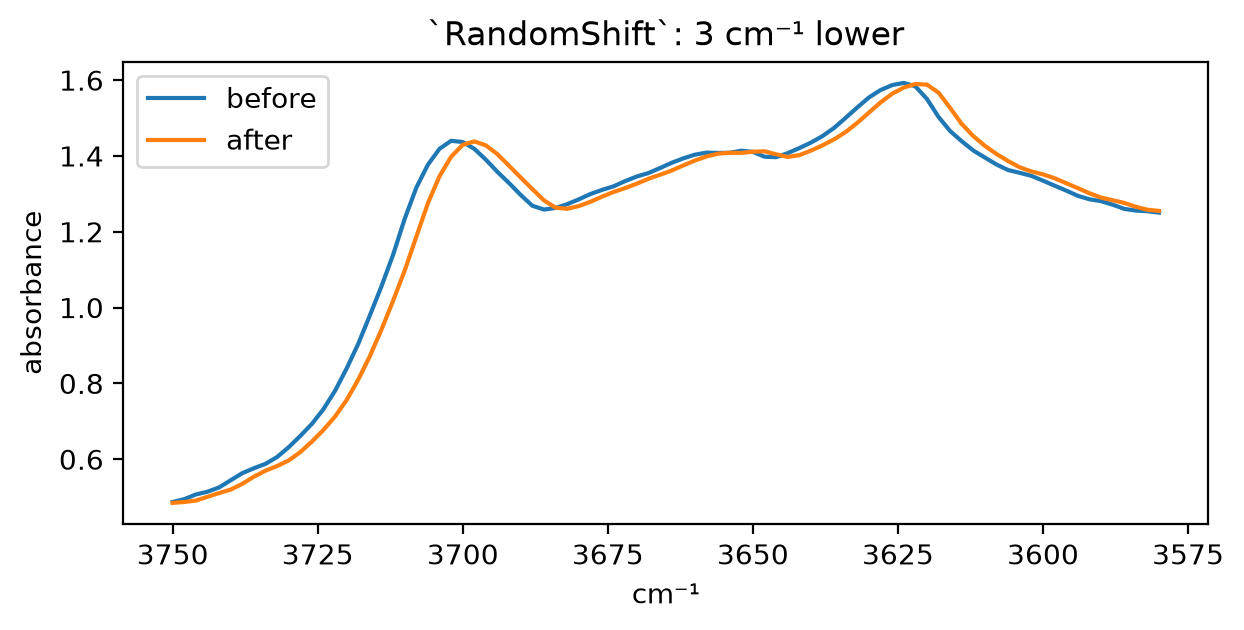

In [11]:
#| rtdata
show(shift_spectra(x0, rt_wns, shift_cm=-3.), '`RandomShift`: 3 cm⁻¹ lower', oh)

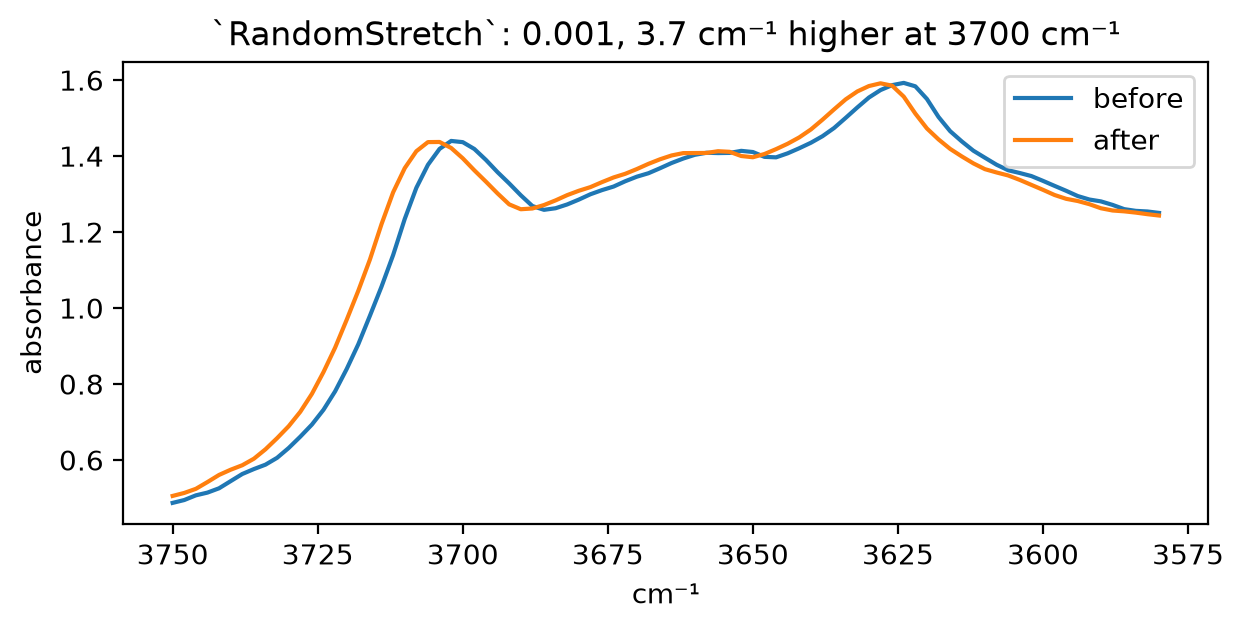

In [12]:
#| rtdata
show(shift_spectra(x0, rt_wns, stretch=1e-3), '`RandomStretch`: 0.001, 3.7 cm⁻¹ higher at 3700 cm⁻¹', oh)

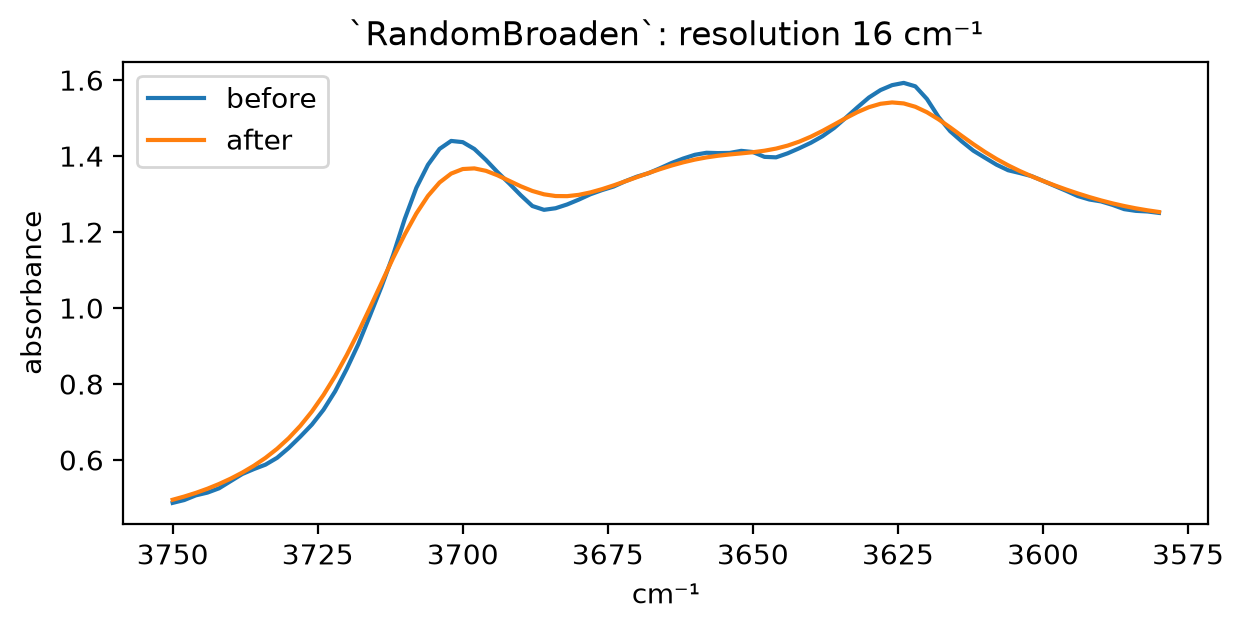

In [13]:
#| rtdata
show(broaden_spectra(x0, np.sqrt(16**2 - 4**2)/2.355, 2.), '`RandomBroaden`: resolution 16 cm⁻¹', oh)

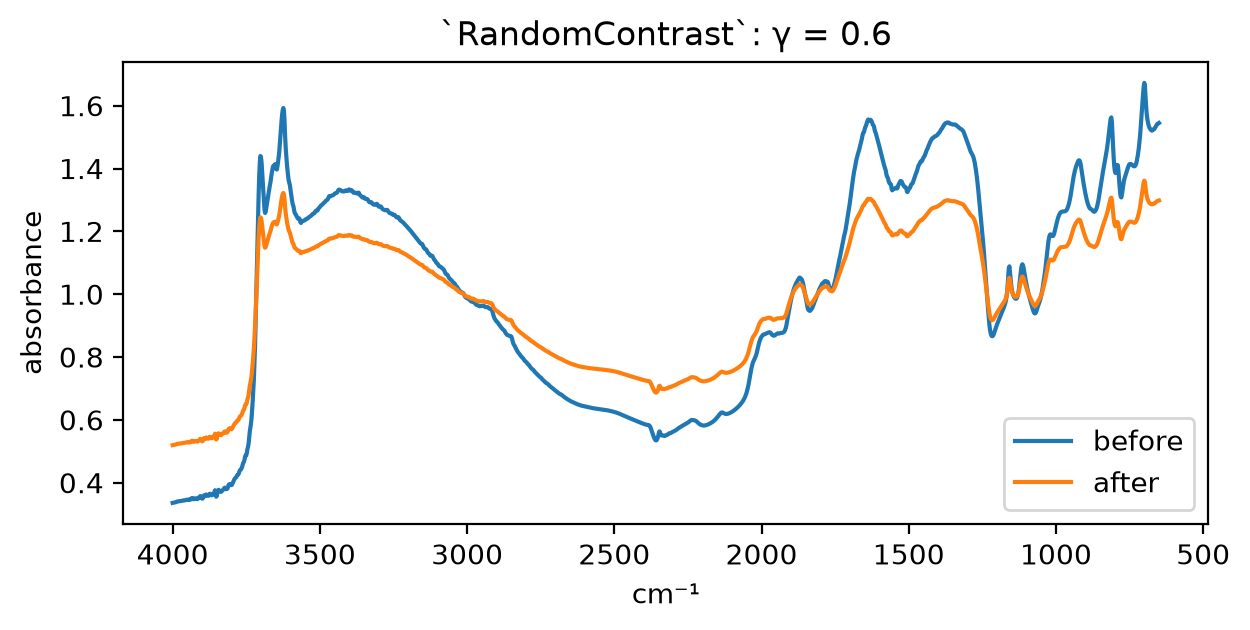

In [14]:
#| rtdata
show(contrast_spectra(x0, 0.6), '`RandomContrast`: γ = 0.6')

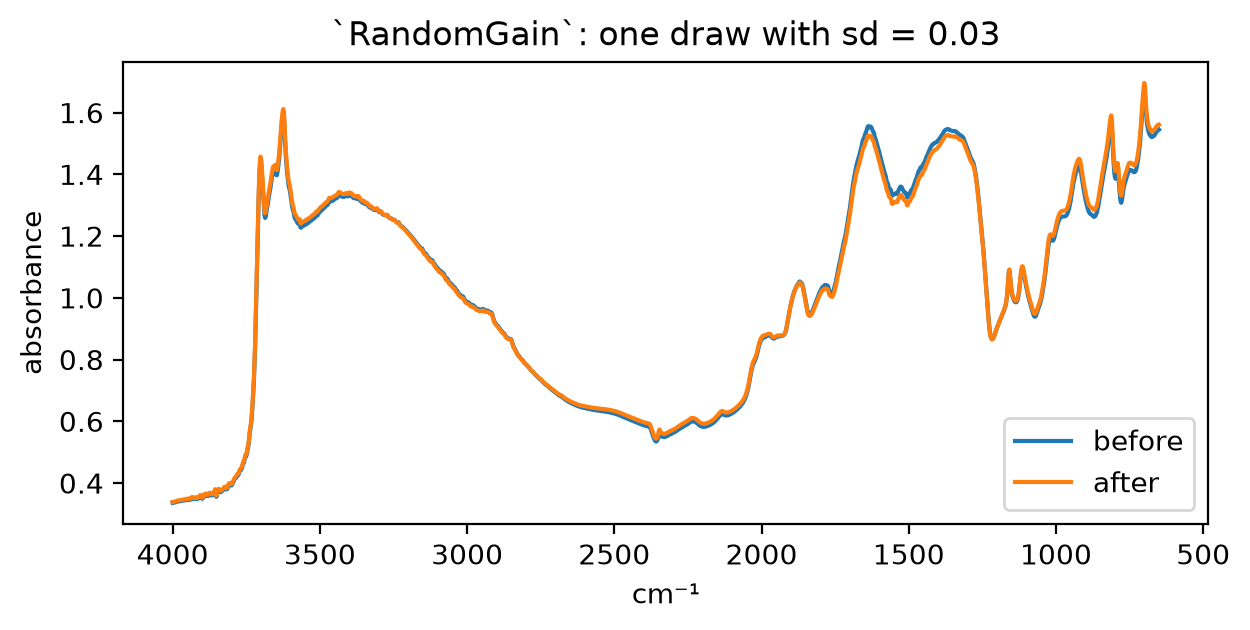

In [15]:
#| rtdata
cg = torch.tensor(np.random.default_rng(1).normal(0, 0.03, (1, 1, 10)), dtype=torch.float32)
show(gain_spectra(x0, B, cg), '`RandomGain`: one draw with sd = 0.03')

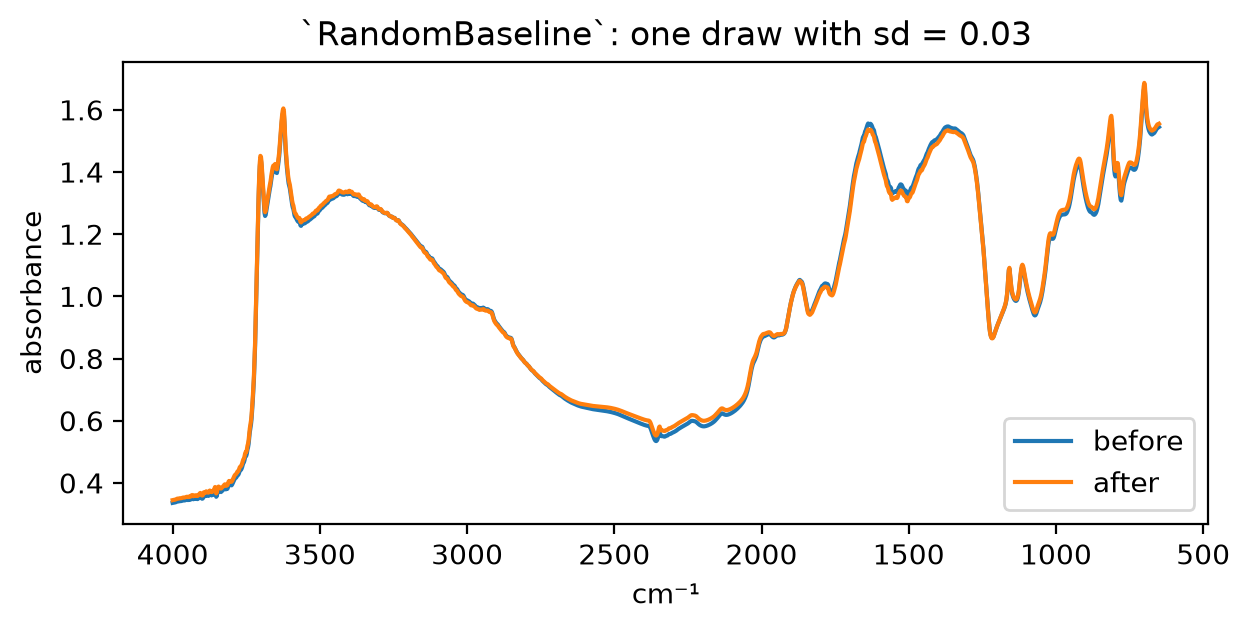

In [16]:
#| rtdata
show(baseline_spectra(x0, B, cg), '`RandomBaseline`: one draw with sd = 0.03')

## Training runs

Clay and K are trained for 20 epochs with seeds 42 and 43, with and without all six transforms at `p=0.5`. The seed sets the validation split and the training, so the OSSL validation R² compares runs with the same seed. The baseline with seed 42 is the 20-epoch model of `01_pretrain`. The augmented runs get absorbance and use `BatchSNV` for the SNV that `preprocess` does in the baseline:

In [17]:
#| rtdata
props, seeds = ['clay_perc', 'potassium_cmolkg'], [42, 43]
def fname(p, aug, seed): return f'ossl_{p}_{"aug" if aug else "snv"}_ep20' + ('' if seed == 42 else f'_seed{seed}')
runs = [(p, aug, s) for p in props for aug in (False, True) for s in seeds]
data = {p: ossl_xy(om, p)[:2] for p in props}
for p, aug, s in runs:
    X, y = data[p]
    if aug: pretrain(X, y, fname(p, aug, s), seed=s, epochs=20, tfm=[*instrument_augs(rt_wns), BatchSNV()])
    else: pretrain(preprocess().fit_transform(X), y, fname(p, aug, s), seed=s, epochs=20)
models = {r: load_pretrained(fname(*r)) for r in runs}

## Results

The cost on OSSL is the validation R² at the last epoch:

In [18]:
#| rtdata
idx = pd.MultiIndex.from_tuples(runs, names=['property', 'augmented', 'seed'])
ossl_r2 = pd.Series([pretrain_history(fname(*r)).r2_score.iloc[-1] for r in runs], index=idx, name='OSSL R²')
ossl_r2.unstack('augmented').round(3)

augmented              False  True 
property         seed              
clay_perc        42    0.883  0.874
                 43    0.891  0.881
potassium_cmolkg 42    0.745  0.733
                 43    0.767  0.749

Augmentation lowers the OSSL validation R² by 0.009 to 0.010 for clay and by 0.012 to 0.018 for K.

Zero-shot scores on the 21 ring-trial instruments, as in `02_zero_shot`, summarised by their median, and the scores on KSSL:

In [19]:
#| rtdata
rtd = load_ringtrial(rt_path())
zs = pd.DataFrame([{'property': p, 'augmented': aug, 'seed': s, 'instrument': k, **zero_shot(models[(p, aug, s)], sp, p)}
                   for p, aug, s in runs for k, sp in rtd.items()])
zs['|bias|'] = zs.bias.abs()
keys = ['property', 'augmented', 'seed']
pd.concat({'median': zs.groupby(keys)[['R²', '|bias|']].median(),
           'KSSL': zs[zs.instrument == 'KSSL'].set_index(keys)[['R²', 'bias']]}, axis=1).round(2)

median         KSSL      
                                    R² |bias|    R²  bias
property         augmented seed                          
clay_perc        False     42     0.60   3.29  0.65  4.71
                           43     0.54   4.57  0.63  5.10
                 True      42     0.69   3.62  0.68  3.77
                           43     0.59   3.25  0.66  4.39
potassium_cmolkg False     42    -0.01   0.28  0.31  0.12
                           43     0.12   0.19  0.35  0.13
                 True      42     0.16   0.20  0.28  0.09
                           43     0.32   0.10  0.32  0.10

With both seeds, augmentation raises the median zero-shot R² over the 21 instruments. For clay it goes from 0.60 to 0.69 with seed 42 and from 0.54 to 0.59 with seed 43. For K, R² is on the `log1p` scale, and it goes from -0.01 to 0.16 and from 0.12 to 0.32. The median |bias| falls for K, from 0.28 to 0.20 and from 0.19 to 0.10 cmol/kg. For clay it rises with seed 42, from 3.29 to 3.62, and falls with seed 43, from 4.57 to 3.25. On KSSL itself, augmentation lowers the clay bias from 4.71 to 3.77 and from 5.10 to 4.39, and changes R² by less than 0.05.

The difference between the two seeds is as large as the gain from augmentation. Two seeds are not enough to give the size of the gain with confidence.

The distance to KSSL measures transfer without the labels. For each instrument and each soil that KSSL also measured, it takes the prediction from the instrument's spectrum minus the prediction from the KSSL spectrum. The table gives the RMS of these differences over all soils and instruments, and the median over instruments of their mean, in `log1p(K)` for K:

In [20]:
#| rtdata
def preds(m, sp): return pd.Series(predict(m, preprocess().fit_transform(sp.spectra), rt_wns).ravel(), index=sp.sample_ids)
def kssl_gap(r):
    pk = preds(models[r], rtd['KSSL'])
    d = {k: (preds(models[r], sp) - pk).dropna() for k, sp in rtd.items() if k != 'KSSL'}
    return {'RMS': np.sqrt(np.mean(np.concatenate([v.values for v in d.values()])**2)), 'median bias': np.median([v.mean() for v in d.values()])}
gap = pd.DataFrame([kssl_gap(r) for r in runs], index=idx)
gap.round(3)

RMS  median bias
property         augmented seed                    
clay_perc        False     42    7.830       -2.494
                           43    8.737       -0.762
                 True      42    7.429       -1.454
                           43    8.240       -1.542
potassium_cmolkg False     42    0.250        0.103
                           43    0.232        0.057
                 True      42    0.231        0.080
                           43    0.209        0.023

Augmentation brings the predictions from the other instruments closer to those from KSSL, but only a little: the RMS distance falls by 5% to 6% for clay and by 8% to 10% for K. The median bias for clay stays between -0.8 and -2.5 percentage points. `04_sensitivity` found that a soil-specific difference shared by the labs explains about a third of the clay gap against KSSL. The augmentation does not model that difference.

The sensitivity check of `04_sensitivity` runs again on the seed-42 models, with 2,000 spectra from their OSSL validation set and the effects at about the sizes that changed the 80-epoch models most:

In [21]:
#| rtdata
cases = {'shift -2 cm⁻¹': dict(shift_cm=-2), 'shift +2 cm⁻¹': dict(shift_cm=2), 'stretch -5e-4': dict(stretch=-5e-4),
         'res 16 cm⁻¹': dict(sigma_cm=np.sqrt(16**2 - 16)/2.355), 'γ 0.6': dict(gamma=0.6), 'γ 1.4': dict(gamma=1.4),
         'gain sd 0.1': dict(gain=np.random.default_rng(0).normal(0, 0.1, 10))}
def valid_sample(p):
    X, y = data[p]
    vi = get_splitter(0.9, 0.1, seed=42)(X, y)[1]
    return X[np.random.default_rng(0).choice(vi, 2000, replace=False)]
sens = pd.concat({(p, aug): sensitivity(models[(p, aug, 42)], valid_sample(p), {k: (lambda X, kw=kw: perturb(X, **kw)) for k, kw in cases.items()}).rms
                  for p in props for aug in (False, True)}, axis=1)
sens.columns.names = ['property', 'augmented']
sens.round(2)

property      clay_perc       potassium_cmolkg      
augmented         False True             False True 
shift -2 cm⁻¹      6.03  1.31             0.19  0.03
shift +2 cm⁻¹      4.18  1.34             0.15  0.03
stretch -5e-4      1.95  0.69             0.13  0.02
res 16 cm⁻¹        6.09  2.13             0.16  0.05
γ 0.6              2.67  1.36             0.09  0.05
γ 1.4              2.35  1.33             0.09  0.04
gain sd 0.1        2.18  1.65             0.06  0.05

The augmented models are much less sensitive to the effects they were trained with. A shift of 2 cm⁻¹ in either direction changes the clay predictions by 1.3 percentage points RMS, against 4.2 to 6.0 without augmentation. Broadening to a resolution of 16 cm⁻¹ changes them by 2.1, against 6.1. For both properties, the changes from shift, stretch and broadening fall by a factor of 3 to 6, and those from contrast by a factor of about 2. The gain case changes least: its standard deviation of 0.1 is outside the training range of 0.03.

## Conclusions

- The augmented models are 3 to 6 times less sensitive to shift, stretch and broadening, and half as sensitive to contrast. They lose about 0.01 in OSSL validation R².
- Zero-shot R² on the ring trial improves for both properties and both seeds, by 0.05 to 0.09 for clay and by 0.17 to 0.20 for K. The variation between seeds is of the same size.
- Predictions from the other instruments move only 5% to 10% closer to those from KSSL. Most of the gap between instruments is therefore not the effects that `InstrumentModel` describes.